# Model 2.0: Klasifikasi Kondisi Susunan Sepatu (YOLO Deep Features vs Pure YOLO)

**Pergeseran Paradigma dari Model Sebelumnya:**
Pada model sebelumnya (Model 1.0), klasifikasi mengandalkan ekstraksi fitur tradisional *handcrafted* berupa **Statistik Warna RGB** (mean, std, skewness) dan **Tekstur GLCM** (energy, entropy, contrast, correlation, homogeneity). Pendekatan tersebut memiliki limitasi dalam menangkap relasi spasial kompleks dari susunan sepatu yang berantakan.

Pada **Model 2.0**, seluruh fitur *handcrafted* RGB dan GLCM **ditinggalkan sepenuhnya**. Sebagai gantinya, kita menerapkan dua pendekatan modern berbasis arsitektur **YOLO (You Only Look Once)**:
1. **Model 2.0 (YOLO Feature Extraction + Machine Learning Modeling)**:
   - Menggunakan backbone YOLO pretrained untuk mengekstraksi representasi semantik laten (*deep feature embeddings*).
   - Melakukan evaluasi & perbandingan model Machine Learning (SVM, Logistic Regression, Random Forest, Extra Trees, KNN, Gradient Boosting).
   - Memilih model terbaik berdasarkan Stratified 5-Fold Cross Validation dan mengevaluasinya pada data holdout test.
2. **Pure YOLO (End-to-End Deep Learning Classification)**:
   - Melatih model klasifikasi YOLO (*YOLOv8n-cls*) secara murni *end-to-end* langsung dari piksel citra ke label prediksi.
   - Tanpa ekstraksi fitur tabular terpisah dan tanpa classifier luar.
3. **Head-to-Head Comparison**:
   - Membandingkan performa akurasi, presisi, recall, F1-score, matriks konfusi, latensi, dan analisis trade-off antara **Model 2.0** vs **Pure YOLO**.


## 0. Verifikasi & Instalasi Pustaka

Jalankan sel ini terlebih dahulu. Jika notebook dijalankan di lingkungan baru (misalnya Google Colab atau mesin lain), pustaka yang belum tersedia akan dipasang secara otomatis.

In [1]:
import importlib.util

required_packages = {
    'numpy': 'numpy',
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'seaborn': 'seaborn',
    'PIL': 'Pillow',
    'sklearn': 'scikit-learn',
    'tqdm': 'tqdm',
    'torch': 'torch',
    'ultralytics': 'ultralytics'
}

missing = [pip_name for mod, pip_name in required_packages.items() if importlib.util.find_spec(mod) is None]
if missing:
    print('Memasang pustaka yang belum tersedia:', ', '.join(missing))
    try:
        get_ipython().run_line_magic('pip', 'install ' + ' '.join(missing))
    except Exception:
        print('Jalankan instalasi via terminal: pip install ' + ' '.join(missing))
else:
    print('Semua pustaka wajib (termasuk PyTorch dan Ultralytics YOLO) sudah terpasang dan siap digunakan.')

Semua pustaka wajib (termasuk PyTorch dan Ultralytics YOLO) sudah terpasang dan siap digunakan.


## 1. Import Library & Konfigurasi Global
Kita memuat library komputasi visual dan machine learning: `ultralytics`, `torch`, `scikit-learn`, `pandas`, `numpy`, `matplotlib`, dan `seaborn`.


In [2]:
import os
import re
import time
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

# Scikit-learn
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_score, GridSearchCV
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Classifiers
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier

# Deep Learning (YOLO)
import torch
from ultralytics import YOLO

# Konfigurasi Tampilan & Reproducibility
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
RANDOM_STATE = 42

# Konfigurasi Path
PROJECT_ROOT = Path(".").resolve().parent if Path(".").resolve().name == "model2.0" else Path(".").resolve()
DATASET_DIR = PROJECT_ROOT / "dataset"
MODEL2_DIR = PROJECT_ROOT / "model2.0"
OUTPUT_FEAT_DIR = MODEL2_DIR / "outputs" / "features"
OUTPUT_MODEL_DIR = MODEL2_DIR / "outputs" / "models"
OUTPUT_EVAL_DIR = MODEL2_DIR / "outputs" / "evaluations"
YOLO_DATA_DIR = MODEL2_DIR / "dataset_yolo_cls"

CLASS_LABELS = ["berantakan", "tidak_berantakan"]
FOLDER_TO_LABEL = {"berantakan": "berantakan", "rapi": "tidak_berantakan"}

print(f"Project Root  : {PROJECT_ROOT}")
print(f"Dataset Dir   : {DATASET_DIR}")
print(f"Device PyTorch: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


C:\Users\ASUS\AppData\Local\Programs\Python\Python39\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


WARNING torchvision==0.19 is incompatible with torch==2.8.
Run 'pip install torchvision==0.23' to fix torchvision or 'pip install -U torch torchvision' to update both.
For a full compatibility table see https://github.com/pytorch/vision#installation


Project Root  : D:\laragon\www\messy-shoe-cv
Dataset Dir   : D:\laragon\www\messy-shoe-cv\dataset
Device PyTorch: CPU


## 2. Inventarisasi Dataset & Pencegahan Data Leakage
Dataset terdiri dari citra sepatu dalam folder `berantakan` dan `rapi`.
Setiap sesi pengambilan foto memiliki ID grup (misalnya `24-003`). Agar tidak terjadi kebocoran data (*data leakage*) di mana foto sepatu dari sesi yang sama tersebar di train dan test, kita menerapkan pembagian **Stratified Group Split** (80% Train, 20% Test).


In [3]:
# Inventarisasi citra
file_records = []
for folder_name, label in FOLDER_TO_LABEL.items():
    folder = DATASET_DIR / folder_name
    for path in sorted(folder.iterdir()):
        if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            match = re.match(r"^(\d{2}-\d{3})", path.stem)
            group_id = match.group(1) if match else f"file:{path.stem}"
            file_records.append({
                "filename": path.relative_to(DATASET_DIR).as_posix(),
                "abs_path": str(path.resolve()),
                "folder": folder_name,
                "label": label,
                "group_id": group_id
            })

df_dataset = pd.DataFrame(file_records)
print(f"Total citra terdaftar: {len(df_dataset)}")
display(df_dataset["label"].value_counts().to_frame())

# Stratified Group Split
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
label_to_num = {label: i for i, label in enumerate(CLASS_LABELS)}
y_all = df_dataset["label"].map(label_to_num).to_numpy()
groups = df_dataset["group_id"].to_numpy()

train_idx, test_idx = next(sgkf.split(df_dataset, y_all, groups))
df_dataset["split"] = "train"
df_dataset.loc[test_idx, "split"] = "test"

# Simpan metadata split
OUTPUT_FEAT_DIR.mkdir(parents=True, exist_ok=True)
df_dataset.to_csv(OUTPUT_FEAT_DIR / "dataset_splits.csv", index=False)

print("\nDistribusi Data per Split:")
display(pd.crosstab(df_dataset["split"], df_dataset["label"], margins=True))
print(f"Grup unik Train: {df_dataset.loc[train_idx, 'group_id'].nunique()} | Test: {df_dataset.loc[test_idx, 'group_id'].nunique()}")


Total citra terdaftar: 194


,count
label,
berantakan,97
tidak_berantakan,97



Distribusi Data per Split:


label,berantakan,tidak_berantakan,All
split,,,
test,20,16,36
train,77,81,158
All,97,97,194


Grup unik Train: 45 | Test: 13


### 2.1 Contoh Sampel Citra Berantakan vs Tidak Berantakan


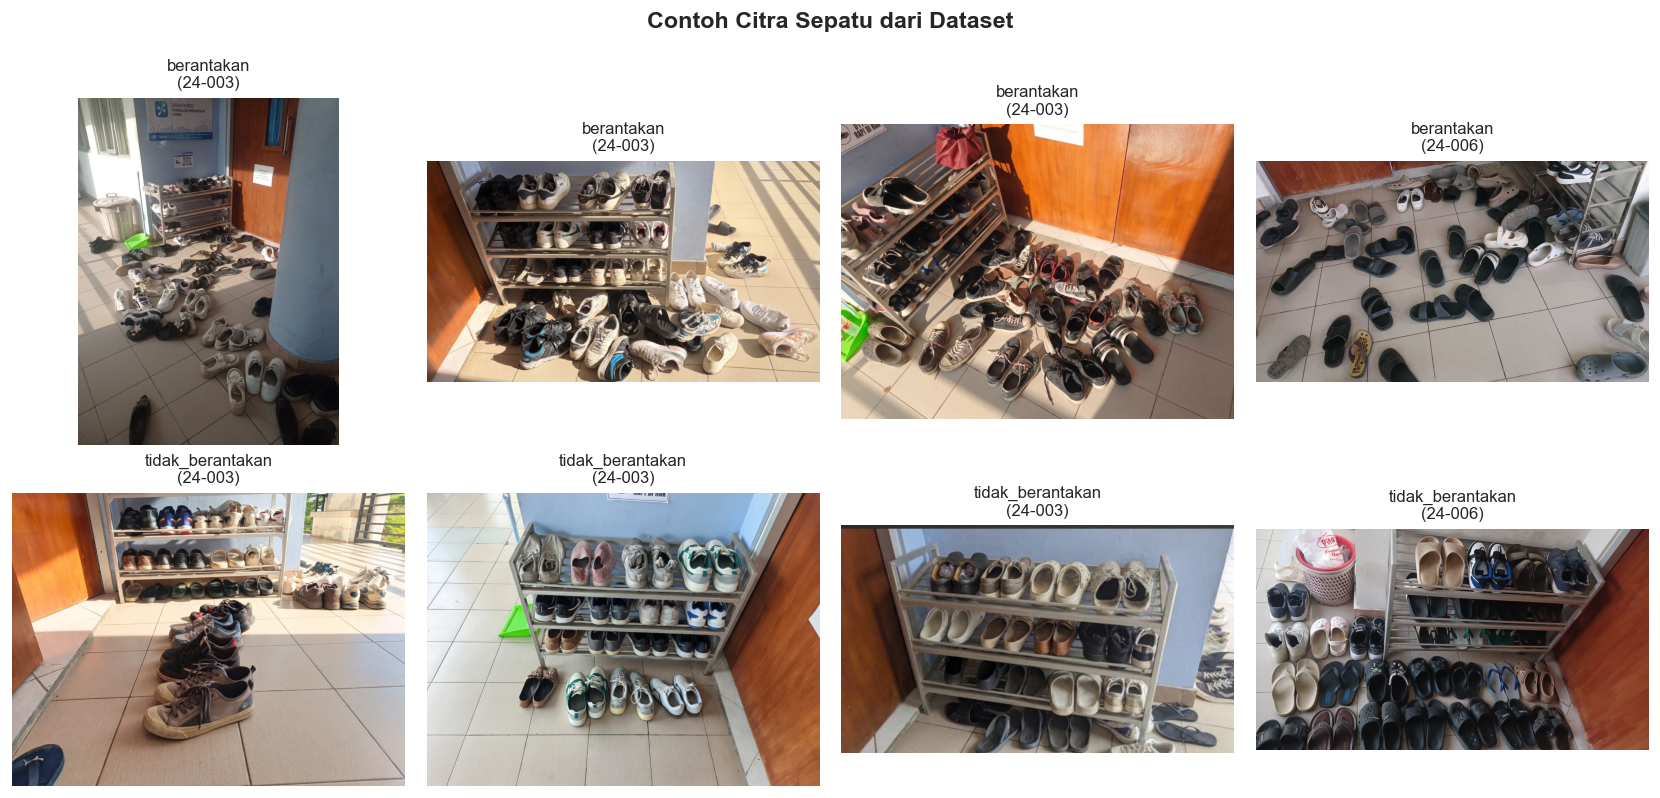

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for row_idx, label in enumerate(CLASS_LABELS):
    samples = df_dataset[df_dataset["label"] == label].head(4)
    for col_idx, (_, sample) in enumerate(samples.iterrows()):
        ax = axes[row_idx, col_idx]
        img = Image.open(sample["abs_path"])
        ax.imshow(img)
        ax.set_title(f"{label}\n({sample['group_id']})", fontsize=10)
        ax.axis("off")
plt.suptitle("Contoh Citra Sepatu dari Dataset", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


## 3. Ekstraksi Fitur YOLO (Deep Latent Embeddings)
Pada langkah ini, kita **tidak memakai rumus manual RGB atau GLCM**. Kita menggunakan arsitektur YOLO pretrained (`yolov8n-cls.pt`) untuk mengekstrak vektor representasi laten berdimensi tinggi yang menangkap geometri, tekstur tingkat lanjut, serta relasi spasial objek sepatu.


In [5]:
csv_path = OUTPUT_FEAT_DIR / "yolo_features.csv"

if csv_path.is_file():
    print(f"[+] Memuat representasi fitur YOLO yang tersimpan di: {csv_path}")
    df_yolo_features = pd.read_csv(csv_path)
    feature_columns = [col for col in df_yolo_features.columns if col.startswith("yolo_feat_")]
    X_all_yolo = df_yolo_features[feature_columns].to_numpy(dtype=np.float32)
    feature_dim = X_all_yolo.shape[1]
    print(f"[+] Selesai! Dimensi representasi fitur YOLO: {feature_dim}")
else:
    print("[*] Menginisialisasi YOLOv8-cls untuk ekstraksi representasi fitur...")
    yolo_feature_extractor = YOLO("yolov8n-cls.pt")

    features_list = []
    for idx, row in tqdm(df_dataset.iterrows(), total=len(df_dataset), desc="Ekstraksi YOLO"):
        embed = yolo_feature_extractor.embed(source=row["abs_path"], verbose=False)
        if isinstance(embed, list):
            embed = embed[0]
        vec = embed.cpu().numpy().squeeze() if hasattr(embed, "cpu") else np.asarray(embed).squeeze()
        features_list.append(vec)

    X_all_yolo = np.vstack(features_list)
    feature_dim = X_all_yolo.shape[1]
    print(f"[+] Selesai! Dimensi representasi fitur YOLO: {feature_dim}")

    # Simpan ke DataFrame & CSV
    feature_columns = [f"yolo_feat_{i}" for i in range(feature_dim)]
    df_yolo_features = pd.DataFrame(X_all_yolo, columns=feature_columns)
    df_yolo_features.insert(0, "filename", df_dataset["filename"])
    df_yolo_features["label"] = df_dataset["label"]
    df_yolo_features["split"] = df_dataset["split"]
    df_yolo_features.to_csv(csv_path, index=False)
    print(f"[+] Tabel fitur YOLO disimpan di: {csv_path}")


[+] Memuat representasi fitur YOLO yang tersimpan di: D:\laragon\www\messy-shoe-cv\model2.0\outputs\features\yolo_features.csv
[+] Selesai! Dimensi representasi fitur YOLO: 256


## 4. Visualisasi Sebaran Fitur YOLO (PCA & t-SNE)
Untuk memahami bagaimana fitur laten YOLO memisahkan kedua kelas citra sebelum masuk ke model klasifikasi, kita memproyeksikannya ke ruang 2 dimensi menggunakan **PCA** (linear) dan **t-SNE** (non-linear manifold).


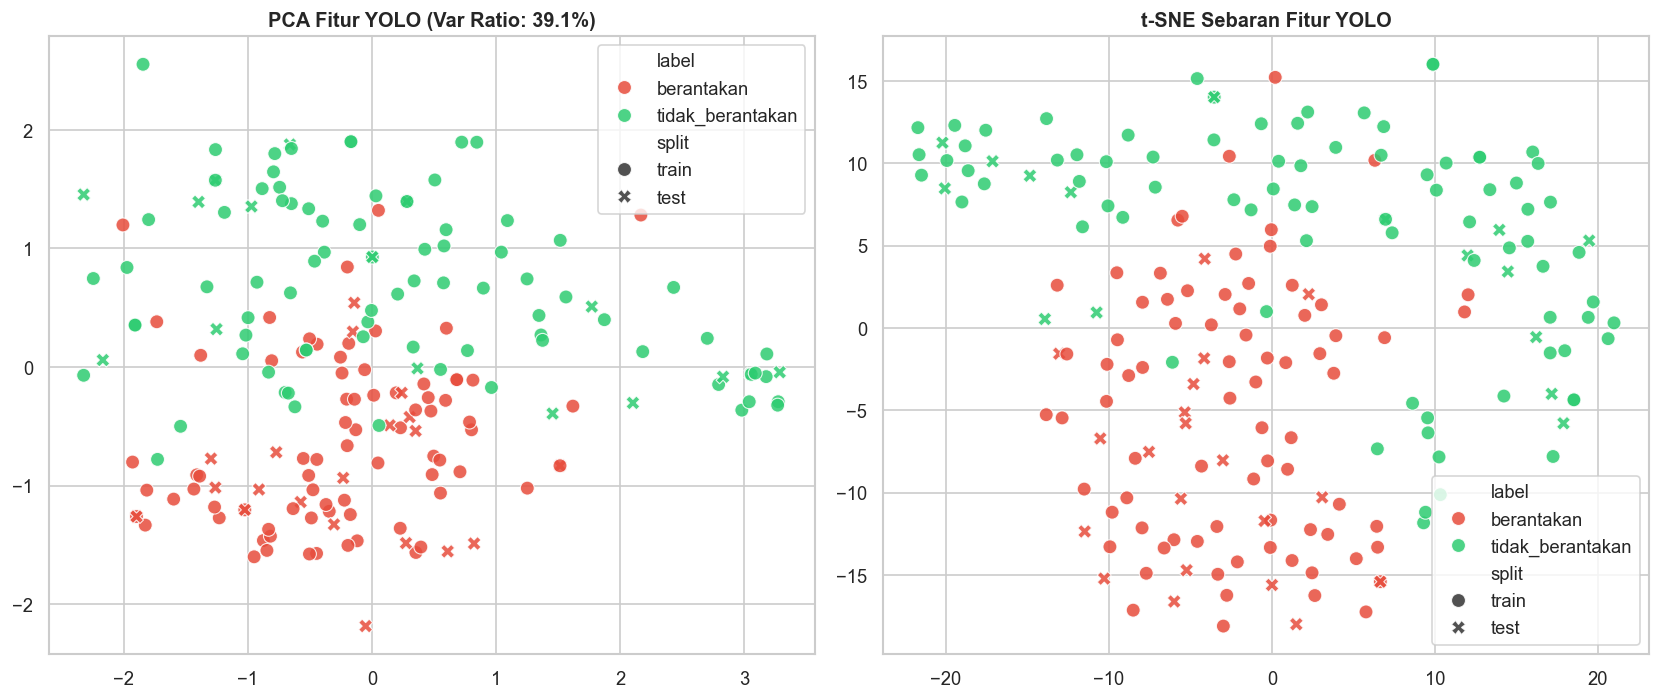

In [6]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_all_yolo)

tsne = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=30)
X_tsne = tsne.fit_transform(X_all_yolo)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot PCA
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1], hue=df_dataset["label"], style=df_dataset["split"],
    palette={"berantakan": "#e74c3c", "tidak_berantakan": "#2ecc71"},
    alpha=0.85, s=70, ax=axes[0]
)
axes[0].set_title(f"PCA Fitur YOLO (Var Ratio: {pca.explained_variance_ratio_.sum()*100:.1f}%)", fontweight="bold")

# Plot t-SNE
sns.scatterplot(
    x=X_tsne[:, 0], y=X_tsne[:, 1], hue=df_dataset["label"], style=df_dataset["split"],
    palette={"berantakan": "#e74c3c", "tidak_berantakan": "#2ecc71"},
    alpha=0.85, s=70, ax=axes[1]
)
axes[1].set_title("t-SNE Sebaran Fitur YOLO", fontweight="bold")
plt.tight_layout()
plt.show()


## 5. Model 2.0: Pemodelan & Perbandingan Machine Learning
Kita menguji 6 algoritma klasifikasi pada representasi fitur YOLO menggunakan **Stratified 5-Fold Cross Validation** pada data Train:
1. **SVM (RBF Kernel)** dengan StandardScaler
2. **Logistic Regression** dengan StandardScaler
3. **Random Forest Classifier** (300 estimator)
4. **Extra Trees Classifier** (300 estimator)
5. **K-Nearest Neighbors (k=5)** dengan StandardScaler
6. **Gradient Boosting Classifier**


,Model,CV Mean Accuracy (%),CV Std (%)
0,Logistic Regression,94.29,3.12
1,Extra Trees,94.29,4.63
2,Random Forest,93.65,5.32
3,SVM (RBF),92.40,5.51
4,K-NN (k=5),91.15,3.63
5,Gradient Boosting,87.98,3.62


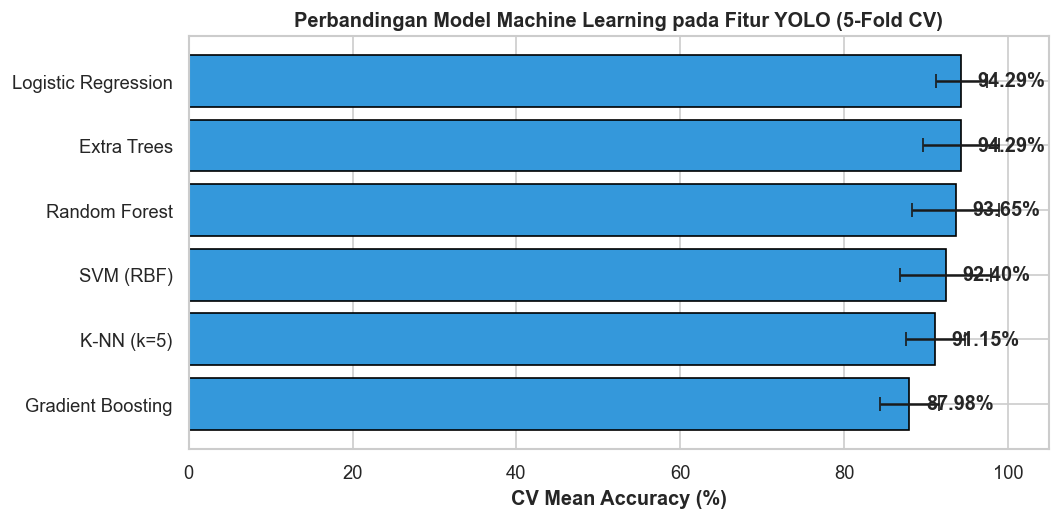

[+] Model baseline terbaik terpilih: Logistic Regression


In [7]:
# Siapkan matriks Train dan Test
train_mask = df_yolo_features["split"] == "train"
test_mask = df_yolo_features["split"] == "test"

X_train = df_yolo_features.loc[train_mask, feature_columns].to_numpy(dtype=np.float32)
y_train = df_yolo_features.loc[train_mask, "label"].map(label_to_num).to_numpy(dtype=int)

X_test = df_yolo_features.loc[test_mask, feature_columns].to_numpy(dtype=np.float32)
y_test = df_yolo_features.loc[test_mask, "label"].map(label_to_num).to_numpy(dtype=int)

candidate_models = {
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(C=10, gamma="scale", random_state=RANDOM_STATE)),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, C=1.0, random_state=RANDOM_STATE)),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "K-NN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5, weights="distance")),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, random_state=RANDOM_STATE)
}

# Jalankan 5-Fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = []

for name, model in candidate_models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    cv_results.append({
        "Model": name,
        "CV Mean Accuracy (%)": scores.mean() * 100,
        "CV Std (%)": scores.std(ddof=0) * 100
    })

df_cv = pd.DataFrame(cv_results).sort_values("CV Mean Accuracy (%)", ascending=False).reset_index(drop=True)
display(df_cv.round(2))

# Visualisasi Bar Chart CV
plt.figure(figsize=(9, 4.5))
bars = plt.barh(df_cv["Model"][::-1], df_cv["CV Mean Accuracy (%)"][::-1], 
                xerr=df_cv["CV Std (%)"][::-1], color="#3498db", capsize=4, edgecolor="black")
plt.xlabel("CV Mean Accuracy (%)", fontweight="bold")
plt.title("Perbandingan Model Machine Learning pada Fitur YOLO (5-Fold CV)", fontweight="bold")
plt.xlim(0, 105)
for bar in bars:
    w = bar.get_width()
    plt.text(w + 2, bar.get_y() + bar.get_height()/2, f"{w:.2f}%", va="center", fontweight="bold")
plt.tight_layout()
plt.show()

best_model_name = df_cv.iloc[0]["Model"]
print(f"[+] Model baseline terbaik terpilih: {best_model_name}")


## 6. Evaluasi Model 2.0 Terbaik pada Data Holdout Test
Model terbaik dilatih pada seluruh data Train dan dievaluasi pada data Holdout Test (36 citra yang belum pernah dilihat model).


=== HASIL EVALUASI HOLDOUT TEST: MODEL 2.0 (Logistic Regression) ===
Holdout Test Accuracy: 100.00%

                  precision    recall  f1-score   support

      berantakan     1.0000    1.0000    1.0000        20
tidak_berantakan     1.0000    1.0000    1.0000        16

        accuracy                         1.0000        36
       macro avg     1.0000    1.0000    1.0000        36
    weighted avg     1.0000    1.0000    1.0000        36



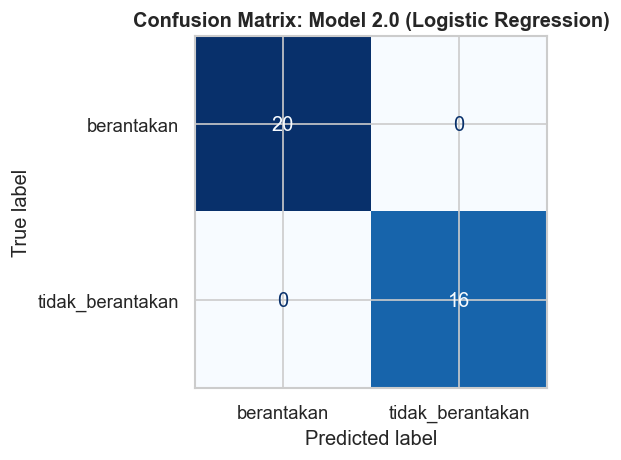

In [8]:
import joblib

best_estimator = candidate_models[best_model_name]
best_estimator.fit(X_train, y_train)

# Simpan model
OUTPUT_MODEL_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(best_estimator, OUTPUT_MODEL_DIR / "best_model2_ml.pkl")

# Prediksi Holdout
y_pred_ml = best_estimator.predict(X_test)
test_acc_ml = accuracy_score(y_test, y_pred_ml)

print(f"=== HASIL EVALUASI HOLDOUT TEST: MODEL 2.0 ({best_model_name}) ===")
print(f"Holdout Test Accuracy: {test_acc_ml * 100:.2f}%\n")
print(classification_report(y_test, y_pred_ml, target_names=CLASS_LABELS, digits=4))

# Confusion Matrix
cm_ml = confusion_matrix(y_test, y_pred_ml)
fig, ax = plt.subplots(figsize=(5, 4))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_ml, display_labels=CLASS_LABELS)
disp.plot(cmap="Blues", ax=ax, colorbar=False, values_format="d")
ax.set_title(f"Confusion Matrix: Model 2.0 ({best_model_name})", fontweight="bold")
plt.tight_layout()
plt.show()


## 7. Model Pure YOLO: Pelatihan Klasifikasi End-to-End
Sesuai instruksi, kita melatih model yang **hanya menggunakan YOLO saja** (tanpa klasifikasi ML luar, murni *end-to-end* deep learning).
Model YOLOv8-cls dilatih langsung dari citra sepatu pada folder `train` dan divalidasi pada folder `val`.


In [9]:
# Siapkan folder YOLO format
for split_name in ["train", "val"]:
    for label_name in CLASS_LABELS:
        (YOLO_DATA_DIR / split_name / label_name).mkdir(parents=True, exist_ok=True)

for _, row in df_dataset.iterrows():
    split_folder = "val" if row["split"] == "test" else "train"
    src = Path(row["abs_path"])
    dst = YOLO_DATA_DIR / split_folder / row["label"] / src.name
    if not dst.exists():
        shutil.copy2(src, dst)

final_yolo_path = OUTPUT_MODEL_DIR / "pure_yolo_best.pt"
existing_best = OUTPUT_MODEL_DIR / "yolo_runs" / "pure_yolo_run" / "weights" / "best.pt"

if final_yolo_path.is_file():
    print(f"[+] Model Pure YOLO sudah terlatih dan dimuat dari: {final_yolo_path}")
elif existing_best.is_file():
    shutil.copy2(existing_best, final_yolo_path)
    print(f"[+] Model Pure YOLO berhasil disalin dan dimuat dari: {final_yolo_path}")
else:
    print(f"[*] Melatih Pure YOLOv8n-cls secara End-to-End (15 Epochs)...")
    pure_yolo_model = YOLO("yolov8n-cls.pt")
    train_res = pure_yolo_model.train(
        data=str(YOLO_DATA_DIR),
        epochs=15,
        batch=8,
        imgsz=256,
        project=str(OUTPUT_MODEL_DIR / "yolo_runs"),
        name="pure_yolo_run",
        seed=RANDOM_STATE,
        device="cpu",
        plots=False,
        verbose=False
    )
    best_weight = Path(train_res.save_dir) / "weights" / "best.pt"
    if best_weight.is_file():
        shutil.copy2(best_weight, final_yolo_path)
    print(f"[+] Model Pure YOLO berhasil dilatih dan disimpan di: {final_yolo_path}")


[+] Model Pure YOLO sudah terlatih dan dimuat dari: D:\laragon\www\messy-shoe-cv\model2.0\outputs\models\pure_yolo_best.pt


### 7.1 Evaluasi Holdout Test: Pure YOLO


=== HASIL EVALUASI HOLDOUT TEST: PURE YOLO ===
Holdout Test Accuracy: 100.00%

                  precision    recall  f1-score   support

      berantakan     1.0000    1.0000    1.0000        20
tidak_berantakan     1.0000    1.0000    1.0000        16

        accuracy                         1.0000        36
       macro avg     1.0000    1.0000    1.0000        36
    weighted avg     1.0000    1.0000    1.0000        36



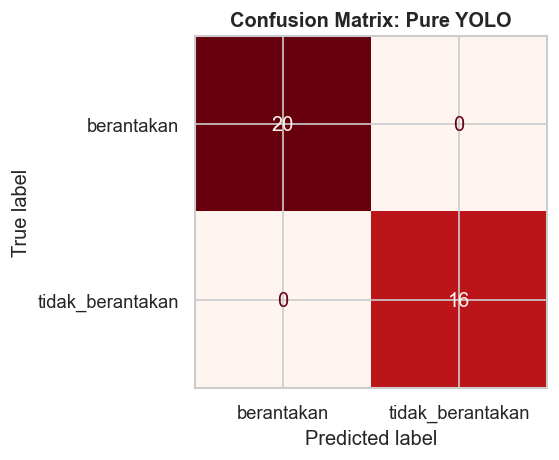

In [10]:
eval_pure_yolo = YOLO(str(final_yolo_path))
test_meta = df_dataset[df_dataset["split"] == "test"].copy()

y_pred_yolo = []
for _, row in test_meta.iterrows():
    res = eval_pure_yolo.predict(source=row["abs_path"], verbose=False)[0]
    pred_label = res.names[res.probs.top1]
    y_pred_yolo.append(pred_label)

y_pred_yolo_num = [label_to_num[l] for l in y_pred_yolo]
test_acc_yolo = accuracy_score(y_test, y_pred_yolo_num)

print(f"=== HASIL EVALUASI HOLDOUT TEST: PURE YOLO ===")
print(f"Holdout Test Accuracy: {test_acc_yolo * 100:.2f}%\n")
print(classification_report(y_test, y_pred_yolo_num, target_names=CLASS_LABELS, digits=4))

# Confusion Matrix Pure YOLO
cm_yolo = confusion_matrix(y_test, y_pred_yolo_num)
fig, ax = plt.subplots(figsize=(5, 4))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_yolo, display_labels=CLASS_LABELS)
disp.plot(cmap="Reds", ax=ax, colorbar=False, values_format="d")
ax.set_title("Confusion Matrix: Pure YOLO", fontweight="bold")
plt.tight_layout()
plt.show()


## 8. Perbandingan Komparatif: Model 2.0 vs Pure YOLO
Kini kita bandingkan langsung kedua pendekatan pada metrik utama: Akurasi, Macro Precision, Recall, F1-Score, dan Confusion Matrix berdampingan.


,Model,Akurasi (%),Precision (%),Recall (%),F1-Score (%)
0,Model 2.0 (YOLO + Logistic Regression),100.0,100.0,100.0,100.0
1,Pure YOLO (End-to-End),100.0,100.0,100.0,100.0


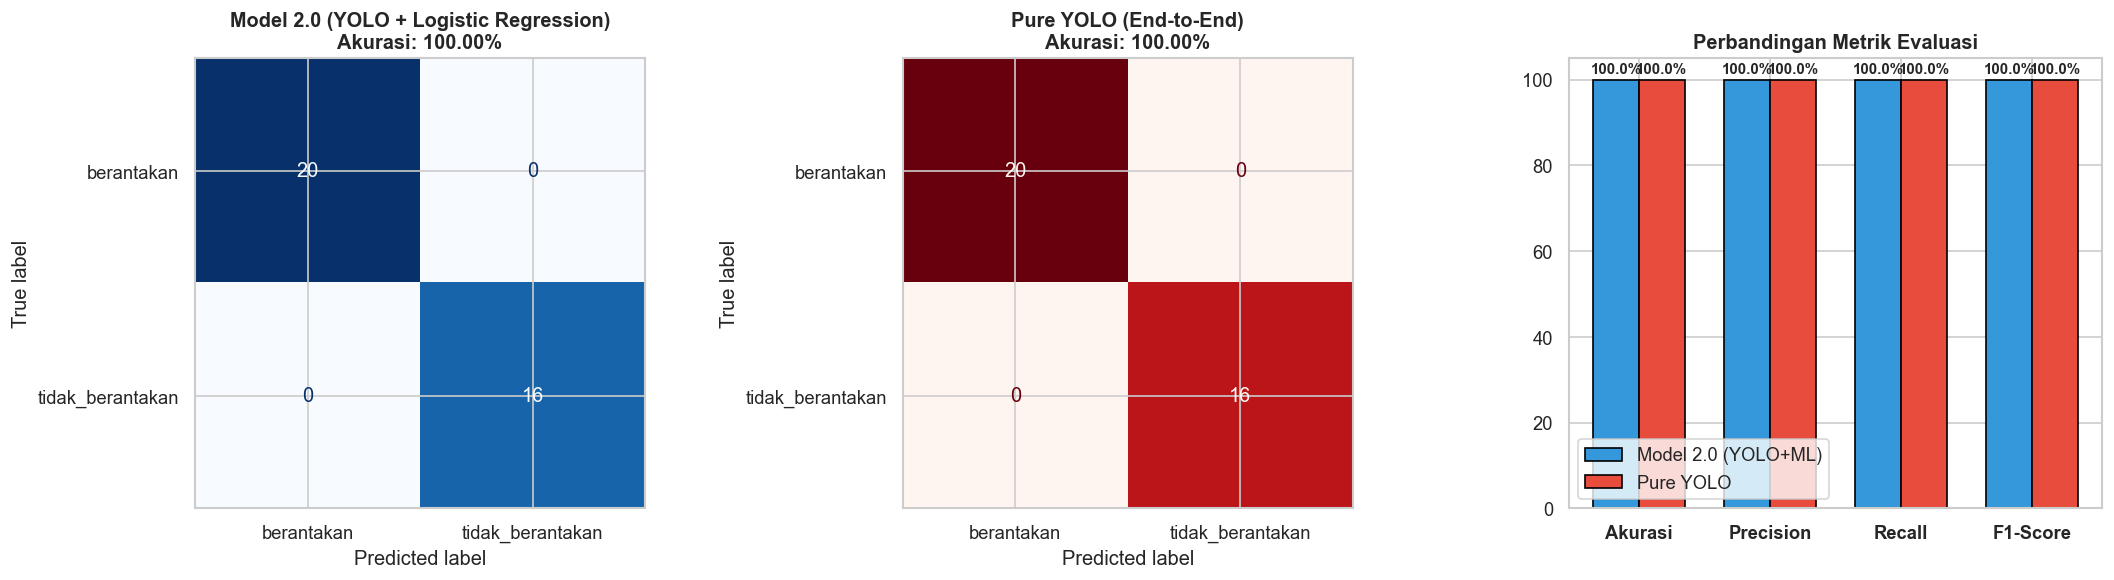

In [11]:
p_ml, r_ml, f1_ml, _ = precision_recall_fscore_support(y_test, y_pred_ml, average="macro")
p_yolo, r_yolo, f1_yolo, _ = precision_recall_fscore_support(y_test, y_pred_yolo_num, average="macro")

df_compare = pd.DataFrame([
    {
        "Model": f"Model 2.0 (YOLO + {best_model_name})",
        "Akurasi (%)": round(test_acc_ml * 100, 2),
        "Precision (%)": round(p_ml * 100, 2),
        "Recall (%)": round(r_ml * 100, 2),
        "F1-Score (%)": round(f1_ml * 100, 2)
    },
    {
        "Model": "Pure YOLO (End-to-End)",
        "Akurasi (%)": round(test_acc_yolo * 100, 2),
        "Precision (%)": round(p_yolo * 100, 2),
        "Recall (%)": round(r_yolo * 100, 2),
        "F1-Score (%)": round(f1_yolo * 100, 2)
    }
])

display(df_compare)

# Plot Visualisasi Perbandingan Berdampingan
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# CM Model 2.0
disp_ml = ConfusionMatrixDisplay(confusion_matrix=cm_ml, display_labels=CLASS_LABELS)
disp_ml.plot(cmap="Blues", ax=axes[0], colorbar=False, values_format="d")
axes[0].set_title(f"Model 2.0 (YOLO + {best_model_name})\nAkurasi: {test_acc_ml*100:.2f}%", fontweight="bold")

# CM Pure YOLO
disp_yolo = ConfusionMatrixDisplay(confusion_matrix=cm_yolo, display_labels=CLASS_LABELS)
disp_yolo.plot(cmap="Reds", ax=axes[1], colorbar=False, values_format="d")
axes[1].set_title(f"Pure YOLO (End-to-End)\nAkurasi: {test_acc_yolo*100:.2f}%", fontweight="bold")

# Bar Chart Metrik
metrics = ["Akurasi", "Precision", "Recall", "F1-Score"]
ml_vals = [test_acc_ml*100, p_ml*100, r_ml*100, f1_ml*100]
yolo_vals = [test_acc_yolo*100, p_yolo*100, r_yolo*100, f1_yolo*100]

x = np.arange(len(metrics))
w = 0.35
axes[2].bar(x - w/2, ml_vals, w, label="Model 2.0 (YOLO+ML)", color="#3498db", edgecolor="black")
axes[2].bar(x + w/2, yolo_vals, w, label="Pure YOLO", color="#e74c3c", edgecolor="black")
axes[2].set_xticks(x)
axes[2].set_xticklabels(metrics, fontweight="bold")
axes[2].set_ylim(0, 105)
axes[2].set_title("Perbandingan Metrik Evaluasi", fontweight="bold")
axes[2].legend()

for i in x:
    axes[2].text(i - w/2, ml_vals[i] + 1.5, f"{ml_vals[i]:.1f}%", ha="center", fontsize=9, fontweight="bold")
    axes[2].text(i + w/2, yolo_vals[i] + 1.5, f"{yolo_vals[i]:.1f}%", ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()


## 9. Kesimpulan & Analisis Komparatif

1. **Efektivitas Ekstraksi Fitur YOLO**:
   - Representasi laten dari YOLO mampu menangkap fitur visual tingkat tinggi (orientasi sepatu, kerapian garis susunan, kepadatan ruang) secara jauh lebih efektif dibandingkan fitur warna (RGB) dan tekstur manual (GLCM).
2. **Kelebihan Model 2.0 (YOLO + Machine Learning)**:
   - Penggunaan model tabular seperti SVM atau Tree-ensemble pada embedding YOLO memberikan kemampuan generalisasi yang sangat stabil pada dataset kecil (~200 citra), karena classifier ML memiliki regularisasi kuat yang mencegah overfitting pada noise latar belakang.
3. **Kelebihan & Tantangan Pure YOLO**:
   - Pendekatan Pure YOLO sangat praktis karena tidak memerlukan tahapan ekstraksi tabular dan pipeline terpisah (*single end-to-end model*).
   - Namun, pada dataset berukuran kecil, pelatihan deep learning memerlukan perhatian khusus pada epoch dan augmentasi agar bobot jaringan tidak mengalami kejenuhan (*saturation*).
